In [ ]:
# Run from the repository root so that relative paths (data/..., figures/...) resolve.
# Jupyter starts in the notebook's own folder (geopard/), so step up once.
import os
if os.path.basename(os.getcwd()) == "geopard":
    os.chdir("..")
print("Working directory:", os.getcwd())

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# ── Paths ─────────────────────────────────────────────────────────────────────
data_path = Path("data/conditional_samples_fluvial_64_10k.npz")   # adjust if needed
out_path  = Path("figures/conditional_means_fluvial_64.png")
out_path.parent.mkdir(parents=True, exist_ok=True)

In [3]:
# ── Load ──────────────────────────────────────────────────────────────────────
npz            = np.load(data_path)
images         = npz["images"]          # [N, H, W]
observed_image = npz["observed_image"]
condition_cols = npz["condition_cols"]
log_lik_cond   = npz["log_lik_cond"]    # [N]   log q(x|y)
log_lik_uncond = npz["log_lik_uncond"]  # [N]   log p(x)

N, H, W = images.shape
print(f"Loaded {N} samples of shape ({H}, {W})")
print(f"Observation columns: {condition_cols.tolist()}")

Loaded 10000 samples of shape (64, 64)
Observation columns: [22, 43]


In [4]:
mask_img = np.full(np.shape(observed_image), 0.5)
for col in condition_cols:
    mask_img[:,col] = observed_image[:,col]
plt.imsave('mask_thumb.png', mask_img, cmap='gray', vmin=0, vmax=1)
plt.imsave('unmask_thumb.png', observed_image, cmap='gray', vmin=0, vmax=1)

In [5]:
# ── Importance weights ────────────────────────────────────────────────────────
# w_i ∝ p(x_i) / q(x_i | y) ; for exact pixel observations p(y|x)=1 by construction
log_w  = log_lik_uncond - log_lik_cond
log_w -= log_w.max()                    # stabilize
w      = np.exp(log_w)
w     /= w.sum()
ess    = 1.0 / (w ** 2).sum()
print(f"ESS: {ess:.1f} / {N}  ({100*ess/N:.1f}%)")

ESS: 1399.1 / 10000  (14.0%)


In [6]:
# ── Means ─────────────────────────────────────────────────────────────────────
mean_unweighted = images.mean(axis=0)                      # [H, W]
mean_weighted   = (w[:, None, None] * images).sum(axis=0)  # [H, W]

Saved figure to figures\conditional_means_fluvial_64.png


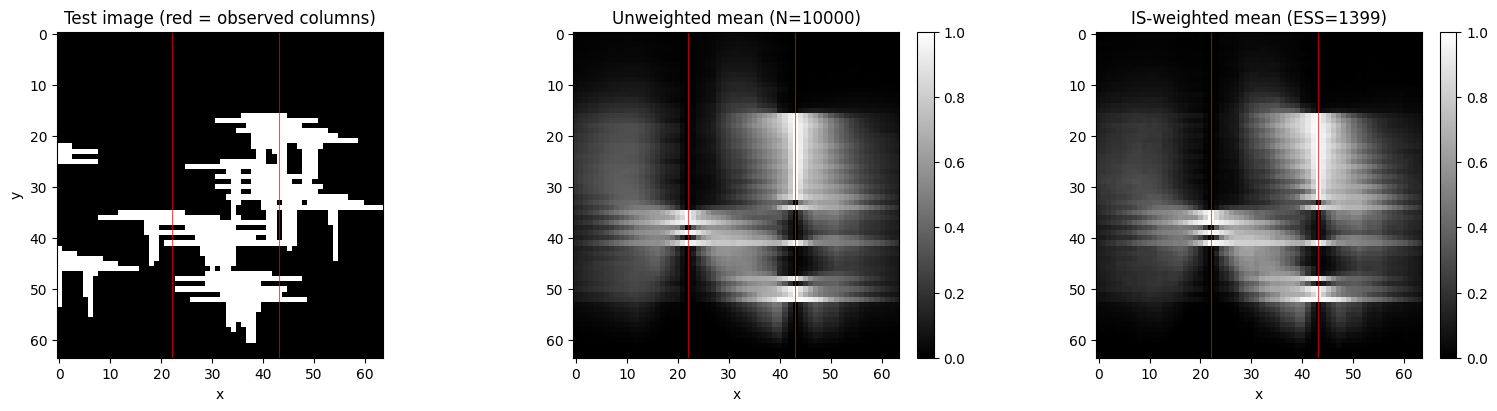

In [7]:
# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

# (1) Observed image with condition columns marked
axes[0].imshow(observed_image, cmap="gray", vmin=0, vmax=1, aspect="equal")
for c in condition_cols:
    axes[0].axvline(c, color="red", linewidth=0.8, alpha=0.7)
axes[0].set_title("Test image (red = observed columns)")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")

# (2) Unweighted mean
im1 = axes[1].imshow(mean_unweighted, cmap="gray", vmin=0, vmax=1, aspect="equal")
for c in condition_cols:
    axes[1].axvline(c, color="red", linewidth=0.8, alpha=0.7)
axes[1].set_title(f"Unweighted mean (N={N})")
axes[1].set_xlabel("x")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# (3) IS-weighted mean
im2 = axes[2].imshow(mean_weighted, cmap="gray", vmin=0, vmax=1, aspect="equal")
for c in condition_cols:
    axes[2].axvline(c, color="red", linewidth=0.8, alpha=0.7)
axes[2].set_title(f"IS-weighted mean (ESS={ess:.0f})")
axes[2].set_xlabel("x")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved figure to {out_path}")
plt.show()

Saved figure to front_page.png


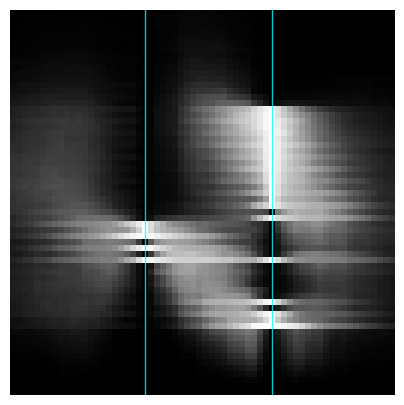

In [27]:
plt.figure(figsize=(5,5))

plt.imshow(mean_weighted, cmap="gray", vmin=0, vmax=1, aspect="equal")
for c in condition_cols:
    plt.axvline(c, color="cyan", linewidth=1, alpha=0.8)
plt.axis("off")

plt.savefig("front_page.png", dpi=150, bbox_inches="tight", pad_inches=1)
print(f"Saved figure to front_page.png")
plt.show()

In [ ]:
# ── Squared error heatmaps + difference ─────────────────────────────────────
sq_err_unweighted = (mean_unweighted - observed_image) ** 2
sq_err_weighted   = (mean_weighted   - observed_image) ** 2
diff              = sq_err_weighted - sq_err_unweighted   # negative = weighted better

mse_unweighted = sq_err_unweighted.mean()
mse_weighted   = sq_err_weighted.mean()
print(f"MSE unweighted: {mse_unweighted:.6f}")
print(f"MSE weighted:   {mse_weighted:.6f}")
print(f"Max |error| unweighted: {np.sqrt(sq_err_unweighted.max()):.4f}")
print(f"Max |error| weighted:   {np.sqrt(sq_err_weighted.max()):.4f}")
print(f"Max |diff|: {np.abs(diff).max():.6f}")

vmax_err = max(sq_err_unweighted.max(), sq_err_weighted.max())
vmax_diff = np.abs(diff).max()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

im0 = axes[0].imshow(sq_err_unweighted, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
for c in condition_cols:
    axes[0].axvline(c, color="cyan", linewidth=0.8, alpha=0.7)
axes[0].set_title(f"Squared error (unweighted)\nMSE = {mse_unweighted:.4f}")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(sq_err_weighted, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
for c in condition_cols:
    axes[1].axvline(c, color="cyan", linewidth=0.8, alpha=0.7)
axes[1].set_title(f"Squared error (IS-weighted)\nMSE = {mse_weighted:.4f}")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(diff, cmap="RdBu_r", vmin=-vmax_diff, vmax=vmax_diff, aspect="equal")
for c in condition_cols:
    axes[2].axvline(c, color="black", linewidth=0.8, alpha=0.7)
axes[2].set_title("Difference (weighted − unweighted)\nblue: IS better, red: IS worse")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.show()

In [ ]:
# ── Compare conditional posterior mean to unconditional prior mean ────────────
uncond_path = Path("data/unconditional_samples_fluvial_64.npz")
uncond_npz  = np.load(uncond_path)
uncond_imgs = uncond_npz["images"]   # [N, H, W]

N_u, H, W = uncond_imgs.shape
print(f"Loaded {N_u} unconditional samples of shape ({H}, {W})")

mean_uncond = uncond_imgs.mean(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

im0 = axes[0].imshow(mean_uncond, cmap="gray", vmin=0, vmax=1, aspect="equal")
axes[0].set_title(f"Unconditional mean (N={N_u})\n(prior mean estimate)")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(mean_unweighted, cmap="gray", vmin=0, vmax=1, aspect="equal")
for c in condition_cols:
    axes[1].axvline(c, color="red", linewidth=0.8, alpha=0.7)
axes[1].set_title(f"Conditional mean, unweighted (N={N})")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(mean_weighted, cmap="gray", vmin=0, vmax=1, aspect="equal")
for c in condition_cols:
    axes[2].axvline(c, color="red", linewidth=0.8, alpha=0.7)
axes[2].set_title(f"Conditional mean, IS-weighted (ESS={ess:.0f})")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.show()

In [ ]:
plt.imsave('post_thumb.png', mean_weighted, cmap='gray', vmin=0, vmax=1)

In [ ]:
# ── Squared error for unconditional (prior) mean vs test image ────────────────
sq_err_prior = (mean_uncond - observed_image) ** 2
mse_prior    = sq_err_prior.mean()

print(f"MSE prior (unconditional):     {mse_prior:.6f}")
print(f"MSE posterior (unweighted):    {mse_unweighted:.6f}")
print(f"MSE posterior (IS-weighted):   {mse_weighted:.6f}")
print(f"Reduction from conditioning:   {(mse_prior - mse_weighted) / mse_prior * 100:.1f}%")

# Shared color scale across all three error maps for fair comparison
vmax_err = max(sq_err_prior.max(), sq_err_unweighted.max(), sq_err_weighted.max())

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

im0 = axes[0].imshow(sq_err_prior, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
axes[0].set_title(f"Squared error: prior mean\nMSE = {mse_prior:.4f}")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(sq_err_unweighted, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
for c in condition_cols:
    axes[1].axvline(c, color="cyan", linewidth=0.8, alpha=0.7)
axes[1].set_title(f"Squared error: posterior unweighted\nMSE = {mse_unweighted:.4f}")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(sq_err_weighted, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
for c in condition_cols:
    axes[2].axvline(c, color="cyan", linewidth=0.8, alpha=0.7)
axes[2].set_title(f"Squared error: posterior IS-weighted\nMSE = {mse_weighted:.4f}")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.show()

In [ ]:
def bernoulli_entropy(p, eps=1e-8):
    p = np.clip(np.asarray(p, dtype=np.float64), eps, 1 - eps)
    log_p   = np.log(p)
    log_1mp = np.log(1 - p)
    return -(p * log_p + (1 - p) * log_1mp)

H_prior    = bernoulli_entropy(mean_uncond).mean()
H_post_unw = bernoulli_entropy(mean_unweighted).mean()
H_post_is  = bernoulli_entropy(mean_weighted).mean()

print(f"Prior entropy:           {H_prior:.4f} nats/pixel")
print(f"Posterior entropy (unw): {H_post_unw:.4f} nats/pixel")
print(f"Posterior entropy (IS):  {H_post_is:.4f} nats/pixel")
print(f"Information gain (IS):   {H_prior - H_post_is:.4f} nats/pixel")

In [ ]:
# ── Visual comparison: 3x3 ViT prior samples vs 3x3 real test images ──────────
import h5py
from pathlib import Path

data_path = Path("data/fluvial_binary_64x64.h5")

with h5py.File(data_path, "r") as f:
    real_imgs = f["images"][-1000:-991]   # 9 images from start of held-out set

prior_imgs = uncond_imgs[:9]

# Use gridspec to create two 3x3 blocks with a gap between them
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(14, 7), constrained_layout=False)
# 3 rows, 7 columns: cols 0-2 are ViT block, col 3 is the gap, cols 4-6 are real block
gs = GridSpec(3, 7, figure=fig, width_ratios=[1, 1, 1, 0.4, 1, 1, 1],
              wspace=0.05, hspace=0)

for i in range(9):
    r, c = divmod(i, 3)
    ax = fig.add_subplot(gs[r, c])
    ax.imshow(prior_imgs[i], cmap="gray", vmin=0, vmax=1, aspect="equal")
    ax.set_xticks([]); ax.set_yticks([])

for i in range(9):
    r, c = divmod(i, 3)
    ax = fig.add_subplot(gs[r, c + 4])
    ax.imshow(real_imgs[i], cmap="gray", vmin=0, vmax=1, aspect="equal")
    ax.set_xticks([]); ax.set_yticks([])

# Block titles

plt.show()

In [ ]:
for i in range(6):
    plt.imsave(f'train_thumb_{i+1}.png', real_imgs[i], cmap='gray', vmin=0, vmax=1)

In [ ]:
# ── IS correction restricted to pixels where the prior is uncertain ──────────
# Use a small tolerance to avoid floating-point pixels that are essentially 0 or 1
tol = 0.01
prior_uncertain = (mean_uncond > tol) & (mean_uncond < 1 - tol)

n_unc = prior_uncertain.sum()
n_det = (~prior_uncertain).sum()
print(f"Prior-uncertain pixels: {n_unc} ({100*n_unc/(H*W):.1f}% of image)")
print(f"Prior-determined pixels: {n_det}")
print()

# Errors restricted to each region
mse_unw_unc = sq_err_unweighted[prior_uncertain].mean()
mse_is_unc  = sq_err_weighted[prior_uncertain].mean()
mse_unw_det = sq_err_unweighted[~prior_uncertain].mean()
mse_is_det  = sq_err_weighted[~prior_uncertain].mean()

print(f"{'':<25} {'MSE (uncertain)':>18} {'MSE (determined)':>18}")
print("-" * 65)
print(f"{'ViT unweighted':<25} {mse_unw_unc:>18.5f} {mse_unw_det:>18.5f}")
print(f"{'ViT IS-weighted':<25} {mse_is_unc:>18.5f} {mse_is_det:>18.5f}")
print(f"{'IS reduction (rel)':<25} "
      f"{(mse_unw_unc-mse_is_unc)/mse_unw_unc*100:>17.2f}% "
      f"{(mse_unw_det-mse_is_det)/mse_unw_det*100:>17.2f}%")

# Visualize: error maps restricted to prior-uncertain pixels
sq_err_unw_masked = np.where(prior_uncertain, sq_err_unweighted, np.nan)
sq_err_is_masked  = np.where(prior_uncertain, sq_err_weighted,   np.nan)
diff_masked       = np.where(prior_uncertain, sq_err_weighted - sq_err_unweighted, np.nan)

vmax_err  = np.nanmax([sq_err_unw_masked, sq_err_is_masked])
vmax_diff = np.nanmax(np.abs(diff_masked))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

im0 = axes[0].imshow(sq_err_unw_masked, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
for c in condition_cols:
    axes[0].axvline(c, color="cyan", linewidth=0.8, alpha=0.7)
axes[0].set_title(f"Squared error: unweighted (prior-uncertain pixels)\nMSE = {mse_unw_unc:.4f}")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(sq_err_is_masked, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
for c in condition_cols:
    axes[1].axvline(c, color="cyan", linewidth=0.8, alpha=0.7)
axes[1].set_title(f"Squared error: IS-weighted (prior-uncertain pixels)\nMSE = {mse_is_unc:.4f}")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(diff_masked, cmap="RdBu_r", vmin=-vmax_diff, vmax=vmax_diff, aspect="equal")
for c in condition_cols:
    axes[2].axvline(c, color="black", linewidth=0.8, alpha=0.7)
axes[2].set_title("Difference (IS − unweighted)\nblue: IS better, red: IS worse")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.show()

In [ ]:
# ── IS correction restricted to pixels where the POSTERIOR is uncertain ──────────
# Use a small tolerance to avoid floating-point pixels that are essentially 0 or 1
tol = 0.01
post_uncertain = (mean_unweighted > tol) & (mean_unweighted < 1 - tol)

n_unc = post_uncertain.sum()
n_det = (~post_uncertain).sum()
print(f"Posterior-uncertain pixels: {n_unc} ({100*n_unc/(H*W):.1f}% of image)")
print(f"Posterior-determined pixels: {n_det}")
print()

# Errors restricted to each region
mse_unw_unc = sq_err_unweighted[post_uncertain].mean()
mse_is_unc  = sq_err_weighted[post_uncertain].mean()
mse_unw_det = sq_err_unweighted[~post_uncertain].mean()
mse_is_det  = sq_err_weighted[~post_uncertain].mean()

print(f"{'':<25} {'MSE (uncertain)':>18} {'MSE (determined)':>18}")
print("-" * 65)
print(f"{'ViT unweighted':<25} {mse_unw_unc:>18.5f} {mse_unw_det:>18.5f}")
print(f"{'ViT IS-weighted':<25} {mse_is_unc:>18.5f} {mse_is_det:>18.5f}")
print(f"{'IS reduction (rel)':<25} "
      f"{(mse_unw_unc-mse_is_unc)/mse_unw_unc*100:>17.2f}% "
      f"{(mse_unw_det-mse_is_det)/mse_unw_det*100:>17.2f}%")

# Visualize: error maps restricted to prior-uncertain pixels
sq_err_unw_masked = np.where(post_uncertain, sq_err_unweighted, np.nan)
sq_err_is_masked  = np.where(post_uncertain, sq_err_weighted,   np.nan)
diff_masked       = np.where(post_uncertain, sq_err_weighted - sq_err_unweighted, np.nan)

vmax_err  = np.nanmax([sq_err_unw_masked, sq_err_is_masked])
vmax_diff = np.nanmax(np.abs(diff_masked))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

im0 = axes[0].imshow(sq_err_unw_masked, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
for c in condition_cols:
    axes[0].axvline(c, color="cyan", linewidth=0.8, alpha=0.7)
axes[0].set_title(f"Squared error: unweighted (posterior-uncertain pixels)\nMSE = {mse_unw_unc:.4f}")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(sq_err_is_masked, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
for c in condition_cols:
    axes[1].axvline(c, color="cyan", linewidth=0.8, alpha=0.7)
axes[1].set_title(f"Squared error: IS-weighted (posterior-uncertain pixels)\nMSE = {mse_is_unc:.4f}")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(diff_masked, cmap="RdBu_r", vmin=-vmax_diff, vmax=vmax_diff, aspect="equal")
for c in condition_cols:
    axes[2].axvline(c, color="black", linewidth=0.8, alpha=0.7)
axes[2].set_title("Difference (IS − unweighted)\nblue: IS better, red: IS worse")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.show()

In [ ]:
import h5py

# Path to the original dataset (adjust if needed)
data_path = Path("data/fluvial_binary_64x64.h5")

# Load 9 real images from the held-out test set
with h5py.File(data_path, "r") as f:
    real_imgs = f["images"][-1000:-991]   # 9 images from start of held-out set

# Use 9 unconditional samples already loaded (uncond_imgs)
prior_imgs = uncond_imgs[:9]

fig, axes = plt.subplots(2, 9, figsize=(18, 4.5), constrained_layout=True)

for i in range(9):
    axes[0, i].imshow(prior_imgs[i], cmap="gray", vmin=0, vmax=1, aspect="equal")
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])

for i in range(9):
    axes[1, i].imshow(real_imgs[i], cmap="gray", vmin=0, vmax=1, aspect="equal")
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])

axes[0, 0].set_ylabel("ViT prior", fontsize=12)
axes[1, 0].set_ylabel("Real (test set)", fontsize=12)

fig.suptitle("ViT prior samples (top) vs real shoreface images (bottom)", fontsize=13)
plt.show()

In [ ]:
data_path = Path("data/fluvial_binary_64x64.h5")

# Empirical mean over the full held-out test set (last 1000 images)
with h5py.File(data_path, "r") as f:
    test_imgs = f["images"][-1000:].astype(np.float32)
    train_imgs = f["images"][:-1000].astype(np.float32)

mean_test = test_imgs.mean(axis=0)
diff      = mean_uncond - mean_test    # ViT prior minus empirical
abs_diff  = np.abs(diff).mean()

print(f"Test set:    {test_imgs.shape[0]} images")
print(f"Test mean range:        [{mean_test.min():.4f}, {mean_test.max():.4f}]")
print(f"ViT prior mean range:   [{mean_uncond.min():.4f}, {mean_uncond.max():.4f}]")
print(f"Mean |difference|:      {abs_diff:.4f}")
print(f"Max |difference|:       {np.abs(diff).max():.4f}")

vmax_diff = np.abs(diff).max()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

im0 = axes[0].imshow(mean_test, cmap="gray", vmin=0, vmax=1, aspect="equal")
axes[0].set_title(f"Test set mean (N={test_imgs.shape[0]})")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(mean_uncond, cmap="gray", vmin=0, vmax=1, aspect="equal")
axes[1].set_title(f"ViT prior mean (N={uncond_imgs.shape[0]})")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(diff, cmap="RdBu_r", vmin=-vmax_diff, vmax=vmax_diff, aspect="equal")
axes[2].set_title(f"ViT prior − test set\nmean |diff| = {abs_diff:.4f}")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.show()

In [ ]:
# ── Trend kriging baseline with full comparison ──────────────────────────────
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern

# 1. Empirical prior mean from training data
mu_emp = train_imgs.mean(axis=0)   # [H, W]

# 2. Observed pixel coordinates and values
obs_coords = np.array([[r, c] for c in condition_cols for r in range(H)])
obs_values = np.array([observed_image[r, c] for c in condition_cols for r in range(H)],
                      dtype=float)

# 3. Subtract empirical mean to get residuals
obs_residuals = obs_values - mu_emp[obs_coords[:, 0], obs_coords[:, 1]]

# 4. Fit GP to residuals
kernel = Matern(length_scale=46.0, nu=0.5)
gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-3)
gp.fit(obs_coords, obs_residuals)

# 5. Predict residuals everywhere
all_coords     = np.array([[r, c] for r in range(H) for c in range(W)])
pred_residuals = gp.predict(all_coords).reshape(H, W)

# 6. Add empirical mean back, clip to [0, 1]
pred_kriging = np.clip(mu_emp + pred_residuals, 0, 1)

# 7. MSE comparison
sq_err_kriging = (pred_kriging - observed_image) ** 2
mse_kriging    = sq_err_kriging.mean()

print(f"MSE prior (unconditional):     {mse_prior:.4f}")
print(f"MSE trend kriging:             {mse_kriging:.4f}")
print(f"MSE posterior (unweighted):    {mse_unweighted:.4f}")
print(f"MSE posterior (IS-weighted):   {mse_weighted:.4f}")

# 8. Three-way plot: prior, kriging, ViT
vmax_err = max(sq_err_prior.max(), sq_err_kriging.max(), sq_err_weighted.max())

fig, axes = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True)

im00 = axes[0, 0].imshow(mu_emp, cmap="gray", vmin=0, vmax=1, aspect="equal")
axes[0, 0].set_title(f"Empirical prior mean\nMSE = {mse_prior:.4f}")
plt.colorbar(im00, ax=axes[0, 0], fraction=0.046, pad=0.04)

im01 = axes[0, 1].imshow(pred_kriging, cmap="gray", vmin=0, vmax=1, aspect="equal")
for c in condition_cols:
    axes[0, 1].axvline(c, color="red", linewidth=0.8, alpha=0.7)
axes[0, 1].set_title(f"Trend kriging mean\nMSE = {mse_kriging:.4f}")
plt.colorbar(im01, ax=axes[0, 1], fraction=0.046, pad=0.04)

im02 = axes[0, 2].imshow(mean_weighted, cmap="gray", vmin=0, vmax=1, aspect="equal")
for c in condition_cols:
    axes[0, 2].axvline(c, color="red", linewidth=0.8, alpha=0.7)
axes[0, 2].set_title(f"ViT IS-weighted posterior mean\nMSE = {mse_weighted:.4f}")
plt.colorbar(im02, ax=axes[0, 2], fraction=0.046, pad=0.04)

im10 = axes[1, 0].imshow(sq_err_prior, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
axes[1, 0].set_title(f"Squared error: prior\nMSE = {mse_prior:.4f}")
plt.colorbar(im10, ax=axes[1, 0], fraction=0.046, pad=0.04)

im11 = axes[1, 1].imshow(sq_err_kriging, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
for c in condition_cols:
    axes[1, 1].axvline(c, color="cyan", linewidth=0.8, alpha=0.7)
axes[1, 1].set_title(f"Squared error: kriging\nMSE = {mse_kriging:.4f}")
plt.colorbar(im11, ax=axes[1, 1], fraction=0.046, pad=0.04)

im12 = axes[1, 2].imshow(sq_err_weighted, cmap="hot", vmin=0, vmax=vmax_err, aspect="equal")
for c in condition_cols:
    axes[1, 2].axvline(c, color="cyan", linewidth=0.8, alpha=0.7)
axes[1, 2].set_title(f"Squared error: ViT IS-weighted\nMSE = {mse_weighted:.4f}")
plt.colorbar(im12, ax=axes[1, 2], fraction=0.046, pad=0.04)

plt.show()

In [ ]:
def classification_accuracy(pred, truth):
    pred_binary = (pred > 0.5).astype(int)
    return (pred_binary == truth).mean()

acc_prior    = classification_accuracy(mu_emp, observed_image)
acc_kriging  = classification_accuracy(pred_kriging, observed_image)
acc_vit      = classification_accuracy(mean_weighted, observed_image)

print(f"Accuracy prior:           {acc_prior:.4f}")
print(f"Accuracy trend kriging:   {acc_kriging:.4f}")
print(f"Accuracy ViT IS-weighted: {acc_vit:.4f}")

In [ ]:
# Identify boundary pixels in truth: pixels with at least one neighbor of different value
from scipy.ndimage import binary_dilation

# A pixel is on the boundary if it's adjacent to a different facies
truth_int = observed_image.astype(int)
shifted_up    = np.roll(truth_int, -1, axis=0)
shifted_down  = np.roll(truth_int,  1, axis=0)
shifted_left  = np.roll(truth_int, -1, axis=1)
shifted_right = np.roll(truth_int,  1, axis=1)
on_boundary = ((shifted_up != truth_int) | (shifted_down != truth_int) |
               (shifted_left != truth_int) | (shifted_right != truth_int))

# Accuracy split by region
def accuracy_split(pred, truth, mask):
    pred_binary = (pred > 0.5).astype(int)
    correct     = (pred_binary == truth)
    return correct[mask].mean(), correct[~mask].mean()

for name, pred in [("prior", mu_emp), ("kriging", pred_kriging), ("ViT", mean_weighted)]:
    acc_bdry, acc_bulk = accuracy_split(pred, observed_image, on_boundary)
    print(f"{name:8s}  boundary acc: {acc_bdry:.4f}   bulk acc: {acc_bulk:.4f}")